# Machine Predictive Maintenance Expert System

**Dataset:** [Machine Predictive Maintenance Classification Dataset](https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification)

**Goal:** Binary classification - `Target`: 0 = No failure, 1 = Failure
> The column `Failure Type` is **excluded** (data leakage)

---
## 1. Imports and Config

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import joblib
import warnings
warnings.filterwarnings('ignore')

---
## 2. Data Loading

In [4]:
df = pd.read_csv('src/predictive_maintenance.csv')

---
## Initial Inspection

In [5]:
print("- Dataset Info -")
print(df.info())

print("\n- Missing Values -")
if(df.isnull().sum().sum() != 0):
    print(df.isnull().sum())
else:
    print("No missing values found.")

- Dataset Info -
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
None

- Missing Values -
No missing values found.


---
## 3. Descriptive statistic

In [6]:
num_features = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

print("- Descriptive statistics of numerical features -")
df[num_features + ['Target']].describe().round(3)

- Descriptive statistics of numerical features -


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,300.005,310.006,1538.776,39.987,107.951,0.034
std,2.000,1.484,179.284,9.969,63.654,0.181
min,295.300,305.700,1168.000,3.800,0.000,0.000
25%,298.300,308.800,1423.000,33.200,53.000,0.000
50%,300.100,310.100,1503.000,40.100,108.000,0.000
75%,301.500,311.100,1612.000,46.800,162.000,0.000
max,304.500,313.800,2886.000,76.600,253.000,1.000


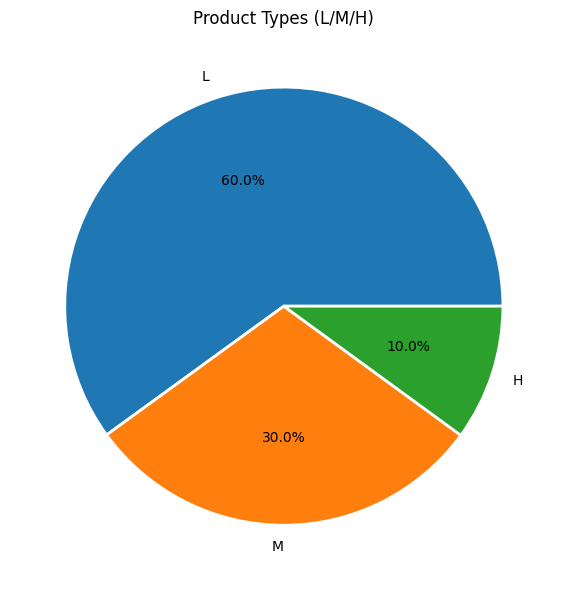

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
tc = df['Type'].value_counts()
ax.pie(tc.values, labels=tc.index, autopct='%1.1f%%', wedgeprops=dict(edgecolor='white', linewidth=2))
ax.set_title('Product Types (L/M/H)')
plt.tight_layout()
plt.show()

In [8]:
print("\n- Failures by product type -")
for t in ['H','M','L']:
    sub = df[df['Type']==t]
    rate = sub['Target'].mean()*100
    print(f"  Type {t}: {sub['Target'].sum():3d}/{len(sub):4d} ({rate:.2f}%)")


- Failures by product type -
  Type H:  21/1003 (2.09%)
  Type M:  83/2997 (2.77%)
  Type L: 235/6000 (3.92%)


---
## 4. Target Distribution

In [9]:
print("- Target variable distribution -")
vc = df['Target'].value_counts()
for k, v in vc.items():
    label = 'Failure     ' if k == 1 else 'No failure'
    print(f"  {label} (Target={k}): {v:5d} samples ({v/len(df)*100:.1f}%)")

if 0 in vc and 1 in vc:
    ratio = vc[0] / vc[1]
    print(f"\nImbalance ratio: {ratio:.1f}:1")
    if ratio > 1.2 or ratio < 0.8:
        print("Dataset is imbalanced!")
    else:
        print("Dataset is balanced.")

- Target variable distribution -
  No failure (Target=0):  9661 samples (96.6%)
  Failure      (Target=1):   339 samples (3.4%)

Imbalance ratio: 28.5:1
Dataset is imbalanced!


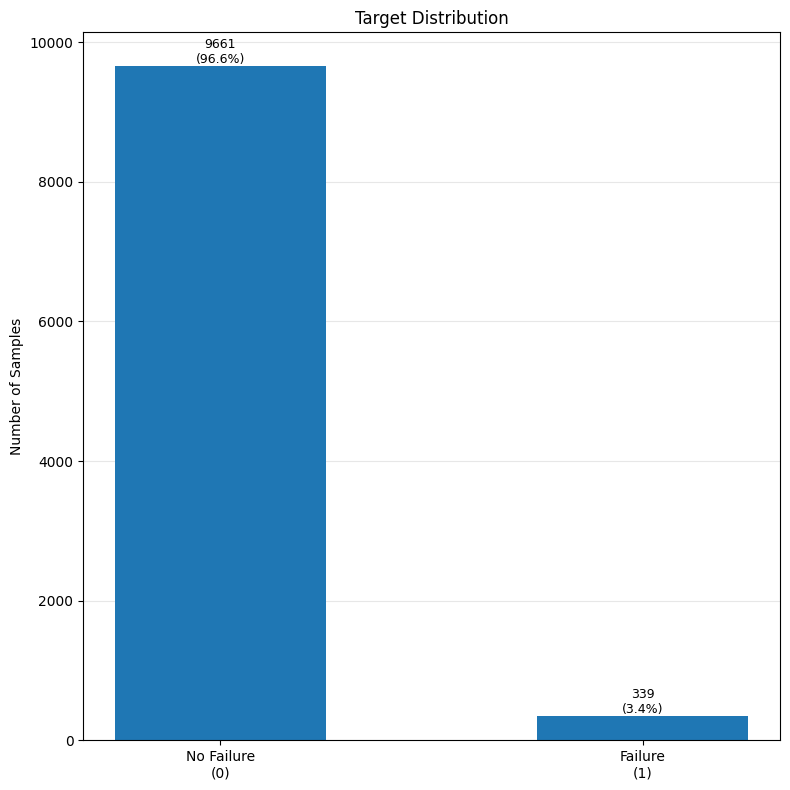

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
counts = df['Target'].value_counts().sort_index()
bars = ax.bar(['No Failure\n(0)', 'Failure\n(1)'], counts.values, width=0.5)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{val}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=9)
ax.set_title('Target Distribution')
ax.set_ylabel('Number of Samples')
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 5. Air Temperature Distribution

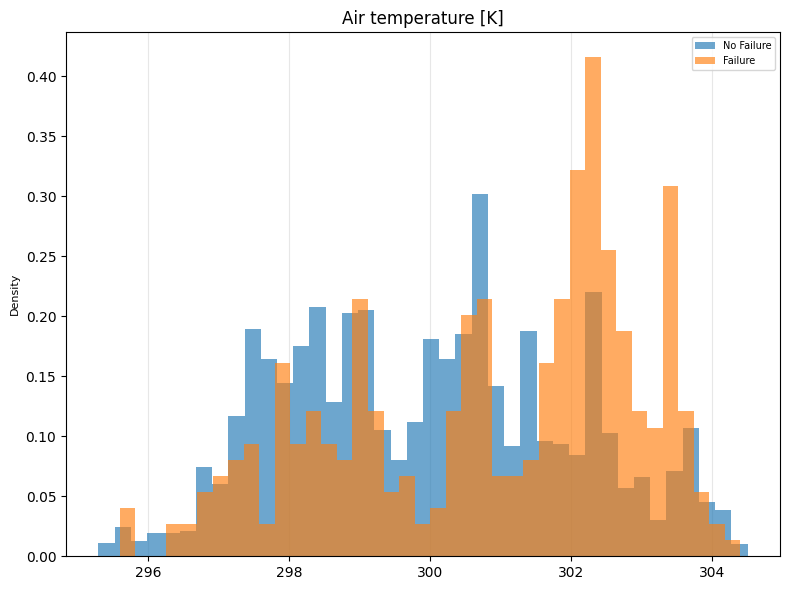

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[0]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 6. Process Temperature Distribution

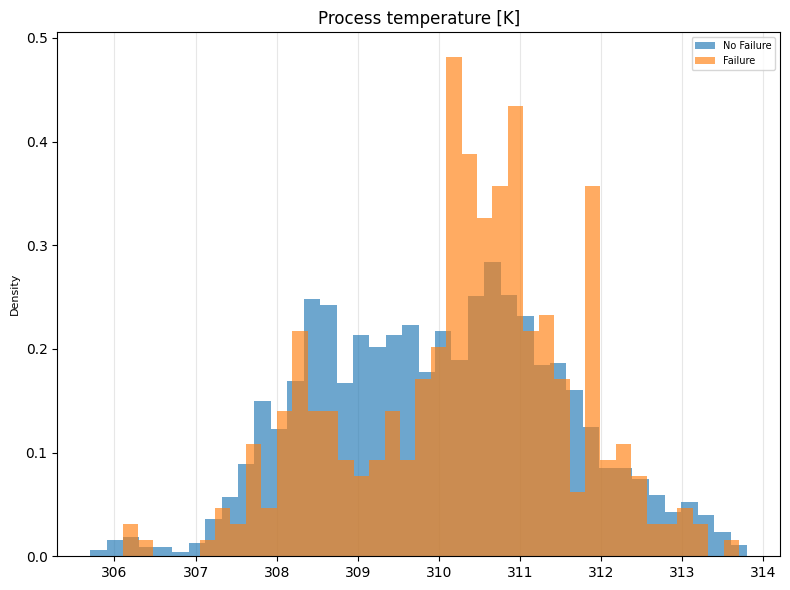

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[1]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 7. RPM Distribution

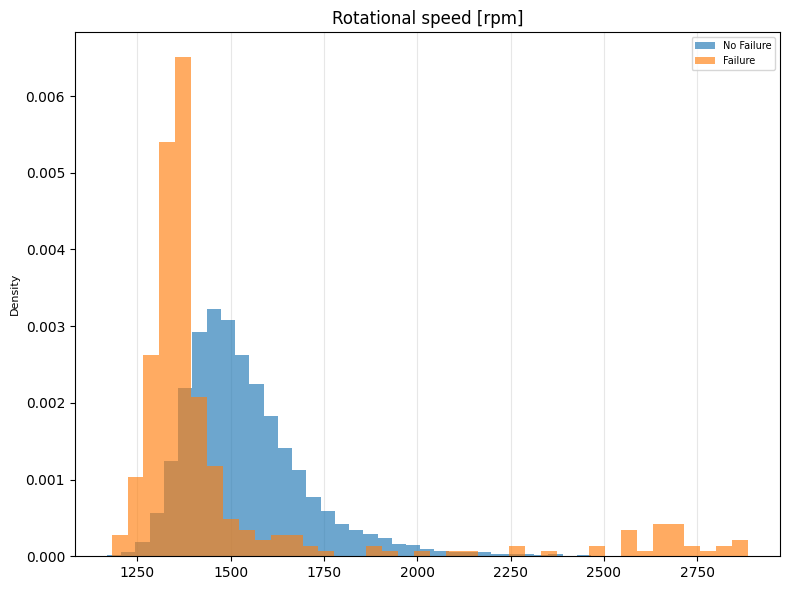

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[2]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 8. Torque Distribution

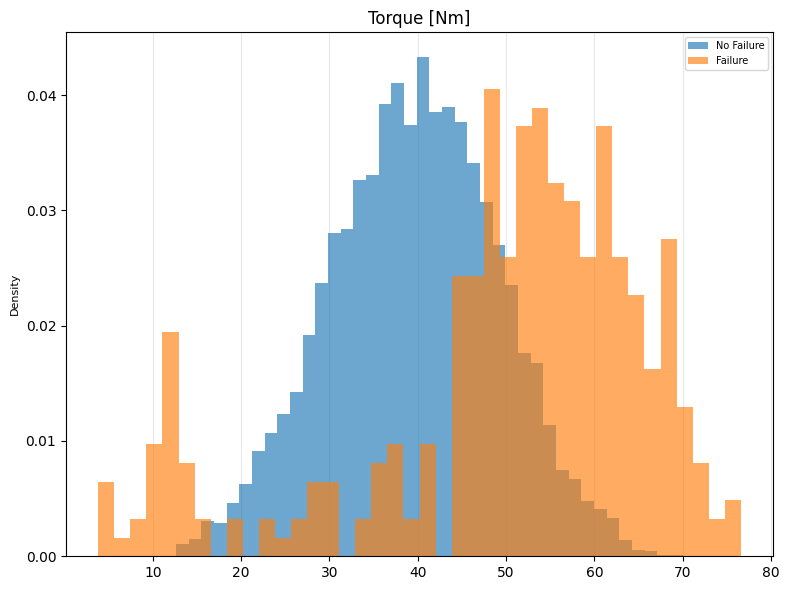

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[3]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 9. Tool Wear Distribution

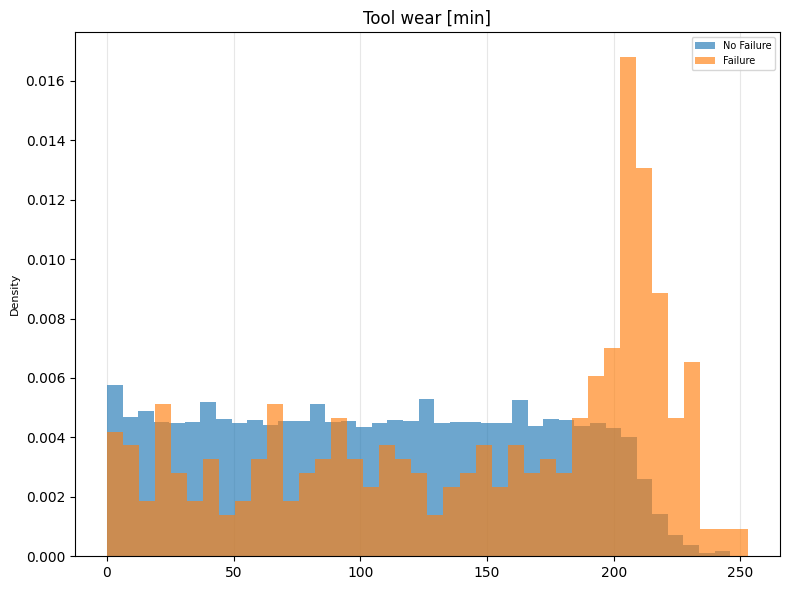

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[4]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 10. Correlation Matrix

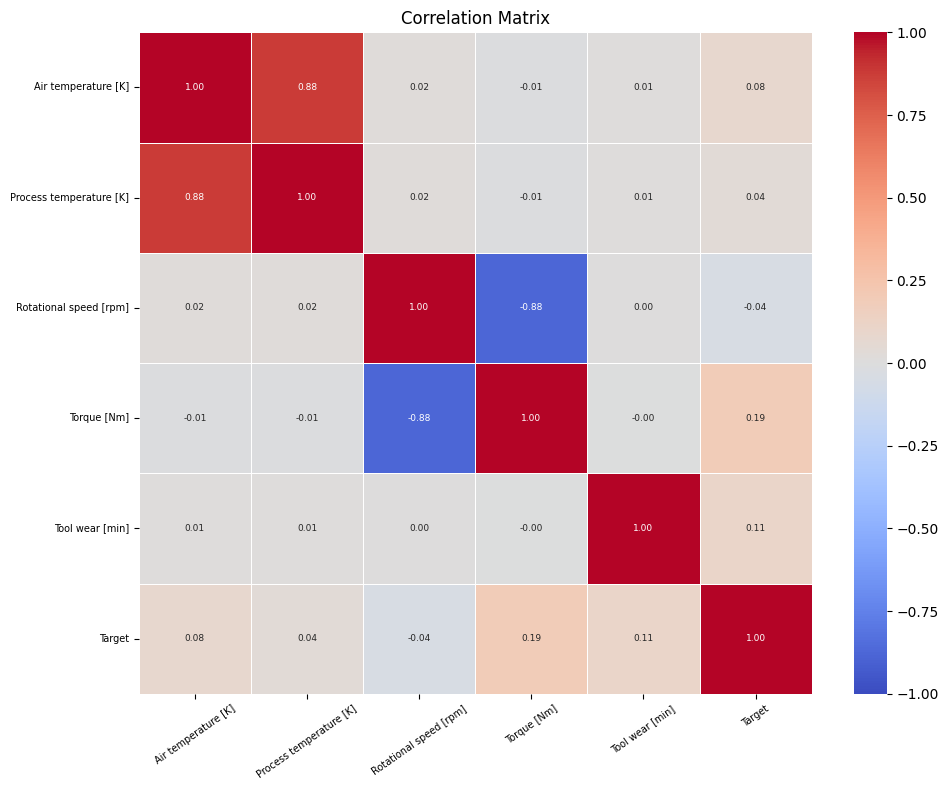

In [16]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df[num_features + ['Target']].corr()
sns.heatmap(corr, ax=ax, cmap='coolwarm', vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 6.5},
            xticklabels=num_features + ['Target'],
            yticklabels=num_features + ['Target'],
            linewidths=0.5, linecolor='white')
ax.set_title('Correlation Matrix')
ax.tick_params(axis='x', rotation=35, labelsize=7)
ax.tick_params(axis='y', rotation=0, labelsize=7)
plt.tight_layout()
plt.show()

---
## 11. Pearson Correlation with Target

In [17]:
le = LabelEncoder()
df['Type_encoded'] = le.fit_transform(df['Type'])

corr_with_target = df[num_features + ['Type_encoded']].corrwith(df['Target']).sort_values(key=abs, ascending=False)
for feat, val in corr_with_target.items():
    print(f"{feat}: {val:+.4f}")

strongest_feat = corr_with_target.index[0]
strongest_val = corr_with_target.iloc[0]
print(f"\nStrongest correlation: {strongest_feat} ({strongest_val:+.4f})")

Torque [Nm]: +0.1913
Tool wear [min]: +0.1054
Air temperature [K]: +0.0826
Rotational speed [rpm]: -0.0442
Process temperature [K]: +0.0359
Type_encoded: -0.0052

Strongest correlation: Torque [Nm] (+0.1913)


---
## 12. Anomaly Analysis

In [18]:
scaler = StandardScaler()
X = df[num_features].values
X_scaled = scaler.fit_transform(X)

print("Feature Standardization:")
print(f"Before: mean={X.mean():.2f}, std={X.std():.2f}")
print(f"After:  mean={X_scaled.mean():.6f}, std={X_scaled.std():.4f}")

Feature Standardization:
Before: mean=459.34, std=556.51
After:  mean=-0.000000, std=1.0000


### 12.1 Z-score (|z| > 3)

In [19]:
z_scores = np.abs(zscore(X_scaled))
zscore_anomaly = (z_scores > 3).any(axis=1)

print(f"Z-score Anomalies (|z|>3): {zscore_anomaly.sum()} samples ({zscore_anomaly.mean()*100:.2f}%)")
print("\nAnomalies per Feature:")
for i, feat in enumerate(num_features):
    cnt = (z_scores[:, i] > 3).sum()
    print(f"{feat}: {cnt} ({cnt/len(df)*100:.2f}%)")

Z-score Anomalies (|z|>3): 178 samples (1.78%)

Anomalies per Feature:
Air temperature [K]: 0 (0.00%)
Process temperature [K]: 0 (0.00%)
Rotational speed [rpm]: 164 (1.64%)
Torque [Nm]: 25 (0.25%)
Tool wear [min]: 0 (0.00%)


### 12.2 IQR Method (1.5 × IQR)

In [20]:
def iqr_anomaly(col):
    Q1, Q3 = col.quantile(0.25), col.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return (col < lower) | (col > upper), lower, upper

iqr_flags = {}
print("IQR Boundaries per Feature:")
for feat in num_features:
    flag, lo, hi = iqr_anomaly(df[feat])
    iqr_flags[feat] = flag
    print(f"{feat}:   [{lo:.2f}, {hi:.2f}]  ->  {flag.sum()} anomalies")

iqr_anomaly_mask = pd.DataFrame(iqr_flags).any(axis=1)
print(f"\nTotal IQR anomalies: {iqr_anomaly_mask.sum()} ({iqr_anomaly_mask.mean()*100:.2f}%)")

IQR Boundaries per Feature:
Air temperature [K]:   [293.50, 306.30]  ->  0 anomalies
Process temperature [K]:   [305.35, 314.55]  ->  0 anomalies
Rotational speed [rpm]:   [1139.50, 1895.50]  ->  418 anomalies
Torque [Nm]:   [12.80, 67.20]  ->  69 anomalies
Tool wear [min]:   [-110.50, 325.50]  ->  0 anomalies

Total IQR anomalies: 459 (4.59%)


### 12.3 Isolation Forest

In [21]:
iso = IsolationForest(contamination=0.05, random_state=42, n_estimators=100)
iso_preds = iso.fit_predict(X_scaled)
iso_anomaly = iso_preds == -1
iso_scores = iso.score_samples(X_scaled)

print(f"Isolation Forest - anomalies: {iso_anomaly.sum()} ({iso_anomaly.mean()*100:.2f}%)")
print("\nConfusion Matrix: IF Anomalies vs Target:")
print(pd.crosstab(iso_anomaly, df['Target'], rownames=['IF Anomaly'], colnames=['Target']))

precision = df.loc[iso_anomaly, 'Target'].mean()
recall = (iso_anomaly & (df['Target']==1)).sum() / df['Target'].sum()
print(f"\nPrecision (IF -> actual failures): {precision:.2%}")
print(f"Recall: {recall:.2%}")

Isolation Forest - anomalies: 500 (5.00%)

Confusion Matrix: IF Anomalies vs Target:
Target         0    1
IF Anomaly           
False       9233  267
True         428   72

Precision (IF -> actual failures): 14.40%
Recall: 21.24%


### 12.4 Local Outlier Factor (LOF)

In [22]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
lof_preds = lof.fit_predict(X_scaled)
lof_anomaly = lof_preds == -1
lof_scores = lof.negative_outlier_factor_

print(f"LOF - anomalies: {lof_anomaly.sum()} ({lof_anomaly.mean()*100:.2f}%)")
print("\nLOF Anomalies vs Target:")
print(pd.crosstab(lof_anomaly, df['Target'], rownames=['LOF Anomaly'], colnames=['Target']))

LOF - anomalies: 500 (5.00%)

LOF Anomalies vs Target:
Target          0    1
LOF Anomaly           
False        9264  236
True          397  103


---
## 13. Anomaly Detection Methods Summary

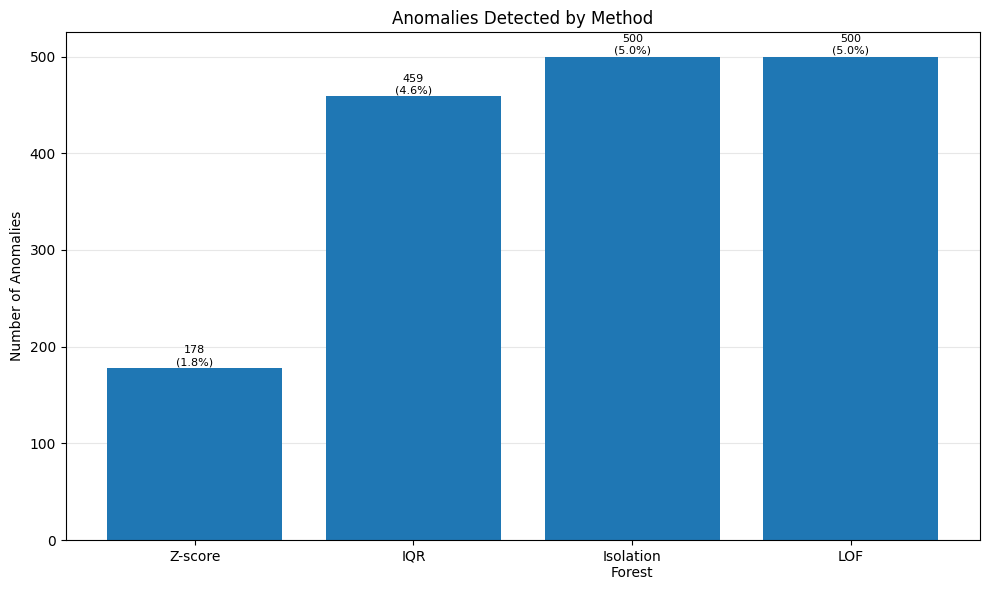

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))
methods = ['Z-score', 'IQR', 'Isolation\nForest', 'LOF']
cnts = [zscore_anomaly.sum(), iqr_anomaly_mask.sum(), iso_anomaly.sum(), lof_anomaly.sum()]
bars = ax.bar(methods, cnts)
for bar, val in zip(bars, cnts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
            f'{val}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=8)
ax.set_title('Anomalies Detected by Method')
ax.set_ylabel('Number of Anomalies')
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 14. RPM Boxplot: Failure vs No Failure

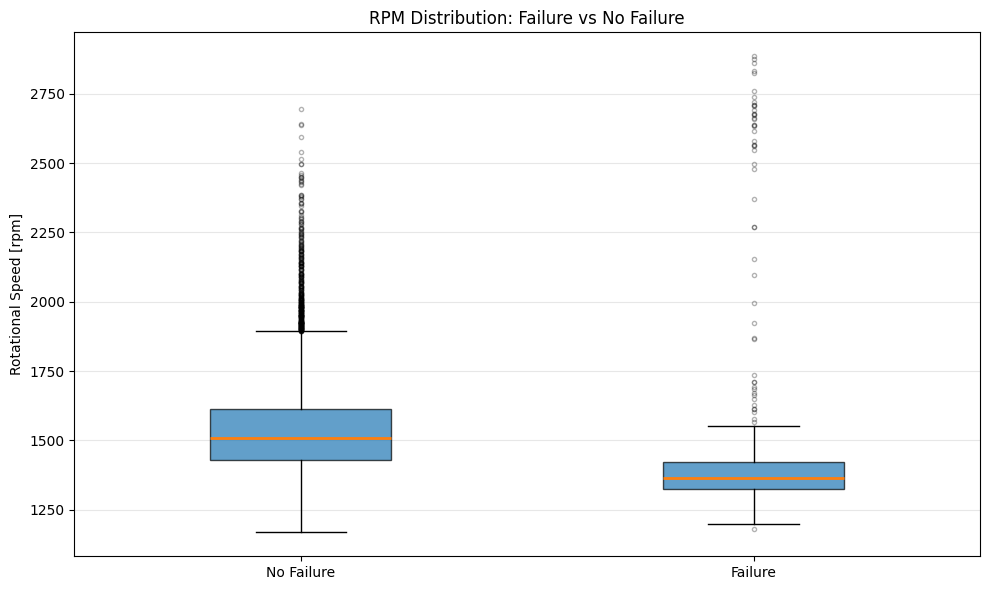

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot([df[df['Target']==0]['Rotational speed [rpm]'].values,
                 df[df['Target']==1]['Rotational speed [rpm]'].values],
                tick_labels=['No Failure', 'Failure'], patch_artist=True, widths=0.4,
                medianprops=dict(linewidth=2),
                flierprops=dict(marker='o', alpha=0.3, markersize=3))
for patch in bp['boxes']:
    patch.set_alpha(0.7)
ax.set_title('RPM Distribution: Failure vs No Failure')
ax.set_ylabel('Rotational Speed [rpm]')
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 15. Isolation Forest vs Target

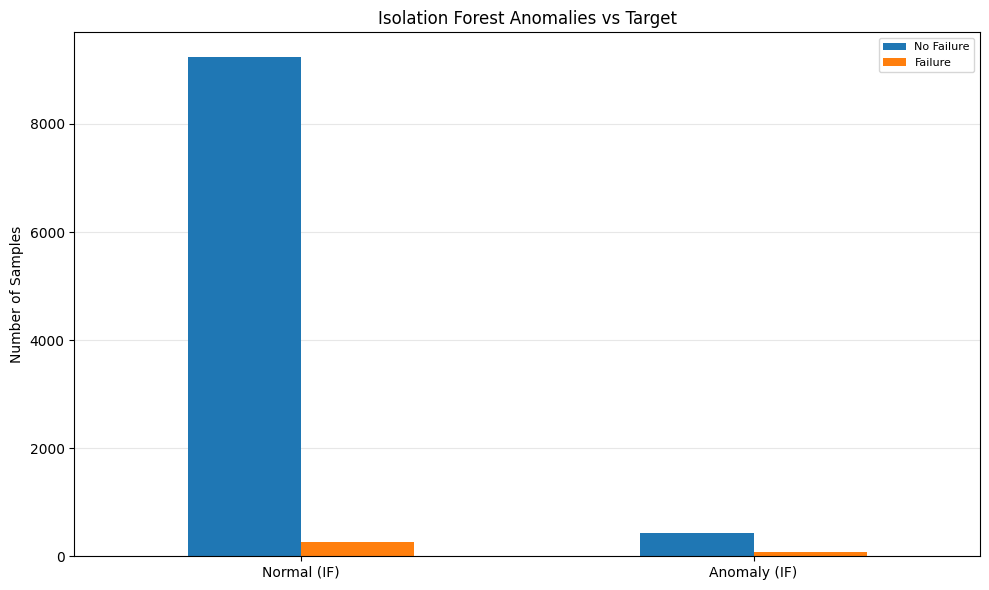

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
ct = pd.crosstab(iso_anomaly, df['Target'])
ct.index = ['Normal (IF)', 'Anomaly (IF)']
ct.columns = ['No Failure', 'Failure']
ct.plot(kind='bar', ax=ax, rot=0)
ax.set_title('Isolation Forest Anomalies vs Target')
ax.set_ylabel('Number of Samples')
ax.legend(fontsize=8)
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 16. Scatter Plot: RPM vs Torque

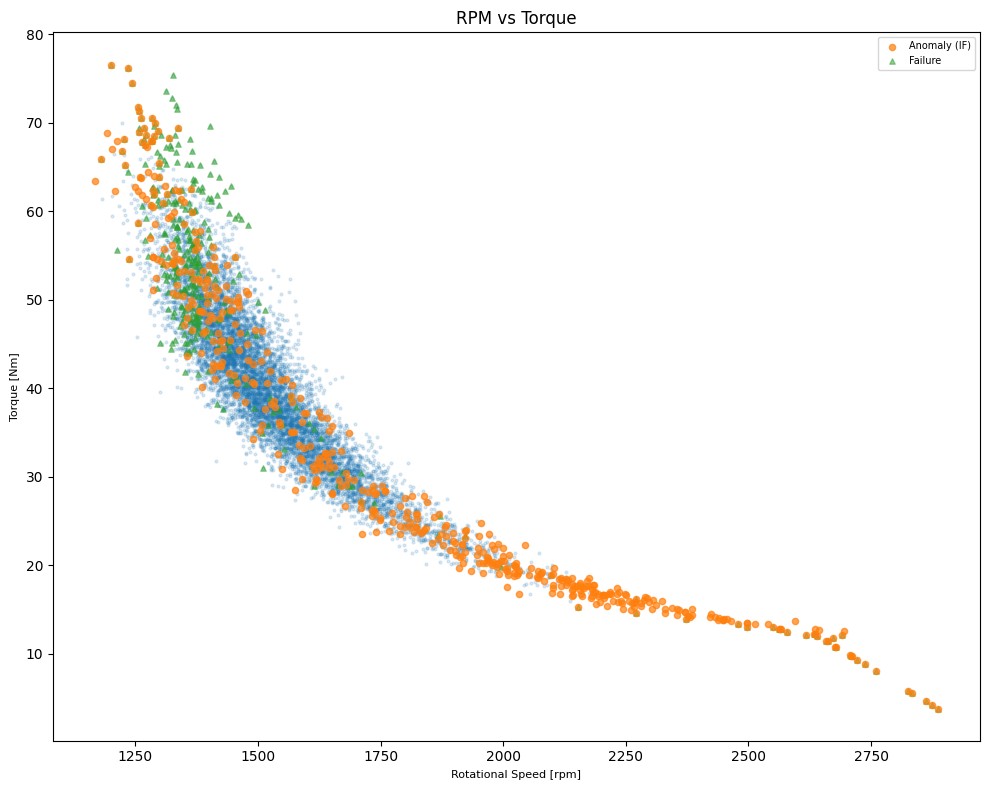

In [26]:
fig, ax = plt.subplots(figsize=(10, 8))
fx, fy = 'Rotational speed [rpm]', 'Torque [Nm]'
ax.scatter(df.loc[~iso_anomaly, fx], df.loc[~iso_anomaly, fy],
           alpha=0.15, s=4, rasterized=True)
ax.scatter(df.loc[iso_anomaly, fx], df.loc[iso_anomaly, fy],
           alpha=0.7, s=20, label='Anomaly (IF)', zorder=5)
ax.scatter(df.loc[df['Target']==1, fx], df.loc[df['Target']==1, fy],
           alpha=0.5, s=15, label='Failure', marker='^', zorder=4)
ax.set_xlabel('Rotational Speed [rpm]', fontsize=8)
ax.set_ylabel('Torque [Nm]', fontsize=8)
ax.set_title('RPM vs Torque')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

---
## 17. Scatter Plot: Air Temp vs Process Temp

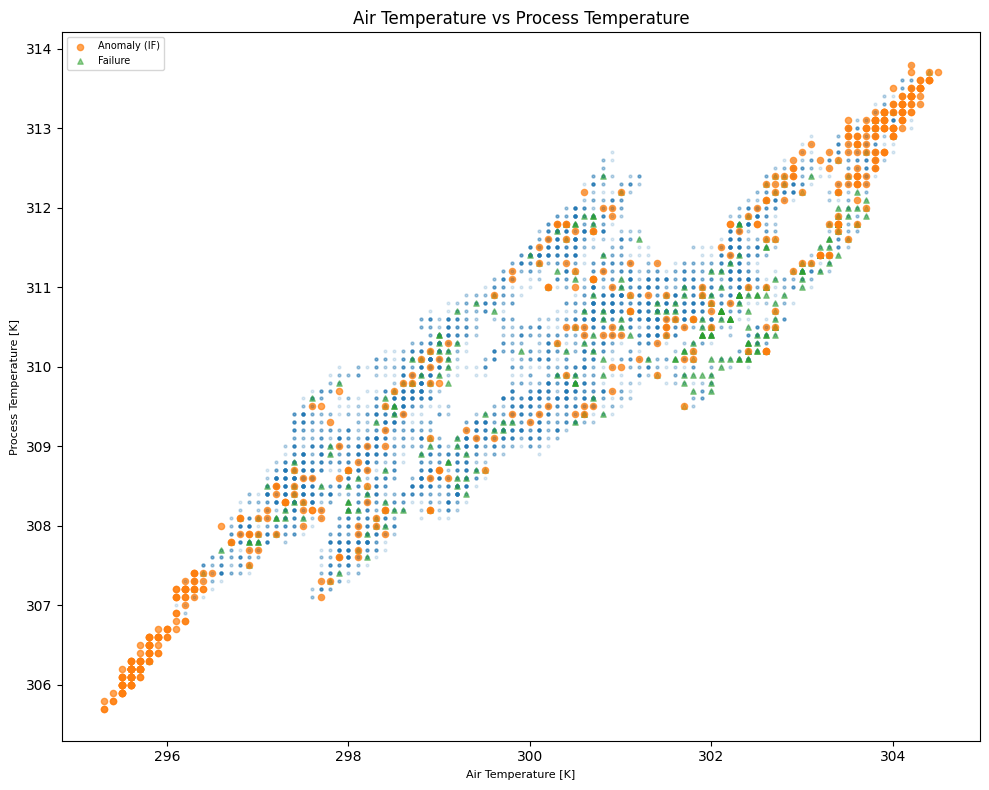

In [27]:
fig, ax = plt.subplots(figsize=(10, 8))
fx, fy = 'Air temperature [K]', 'Process temperature [K]'
ax.scatter(df.loc[~iso_anomaly, fx], df.loc[~iso_anomaly, fy],
           alpha=0.15, s=4, rasterized=True)
ax.scatter(df.loc[iso_anomaly, fx], df.loc[iso_anomaly, fy],
           alpha=0.7, s=20, label='Anomaly (IF)', zorder=5)
ax.scatter(df.loc[df['Target']==1, fx], df.loc[df['Target']==1, fy],
           alpha=0.5, s=15, label='Failure', marker='^', zorder=4)
ax.set_xlabel('Air Temperature [K]', fontsize=8)
ax.set_ylabel('Process Temperature [K]', fontsize=8)
ax.set_title('Air Temperature vs Process Temperature')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

---
## 18. Scatter Plot: Tool Wear vs Torque

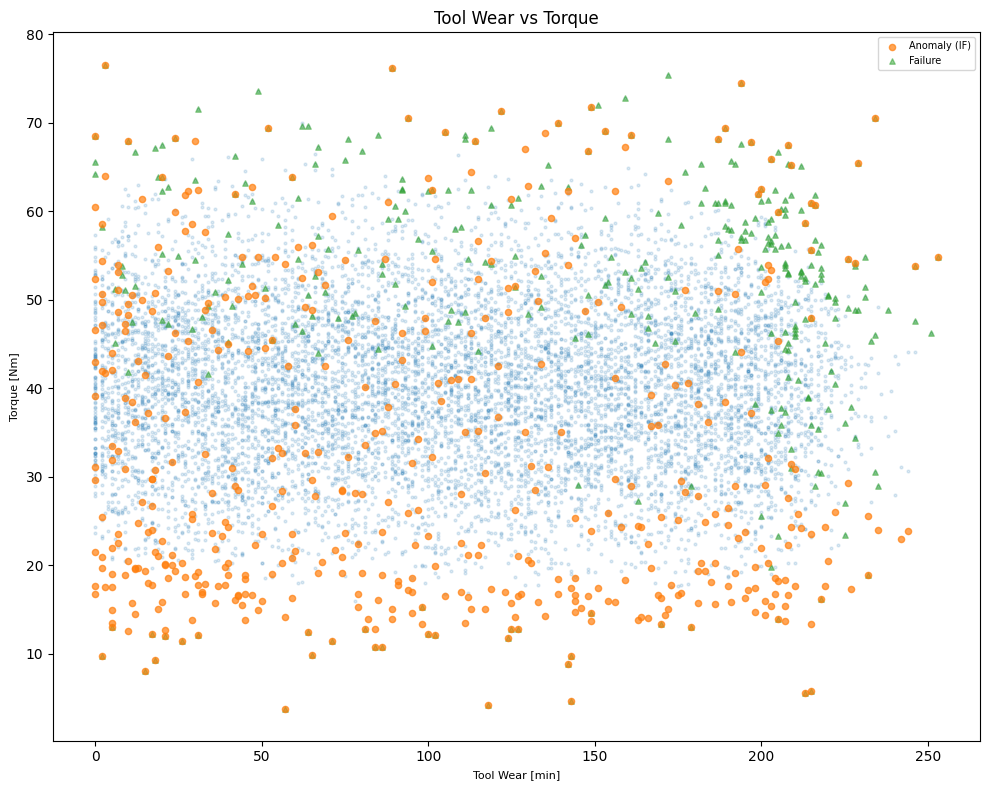

In [28]:
fig, ax = plt.subplots(figsize=(10, 8))
fx, fy = 'Tool wear [min]', 'Torque [Nm]'
ax.scatter(df.loc[~iso_anomaly, fx], df.loc[~iso_anomaly, fy],
           alpha=0.15, s=4, rasterized=True)
ax.scatter(df.loc[iso_anomaly, fx], df.loc[iso_anomaly, fy],
           alpha=0.7, s=20, label='Anomaly (IF)', zorder=5)
ax.scatter(df.loc[df['Target']==1, fx], df.loc[df['Target']==1, fy],
           alpha=0.5, s=15, label='Failure', marker='^', zorder=4)
ax.set_xlabel('Tool Wear [min]', fontsize=8)
ax.set_ylabel('Torque [Nm]', fontsize=8)
ax.set_title('Tool Wear vs Torque')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

---
## 19. Z-score Anomalies per Feature

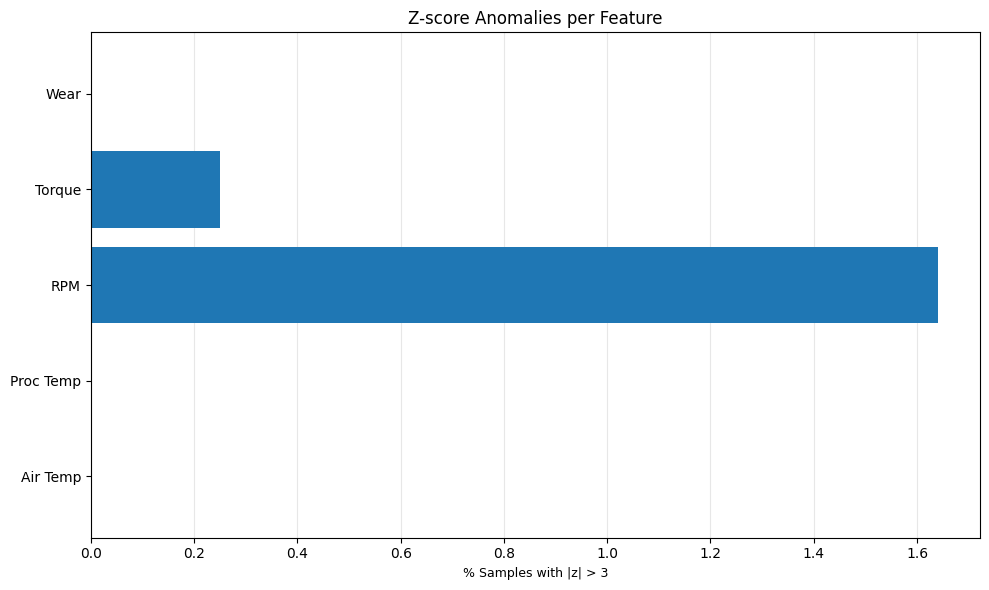

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))
z_per = (np.abs(zscore(df[num_features])) > 3).mean(axis=0) * 100
feat_short = ['Air Temp', 'Proc Temp', 'RPM', 'Torque', 'Wear']
ax.barh(feat_short, z_per)
ax.set_title('Z-score Anomalies per Feature')
ax.set_xlabel('% Samples with |z| > 3', fontsize=9)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 20. LOF Score Distribution

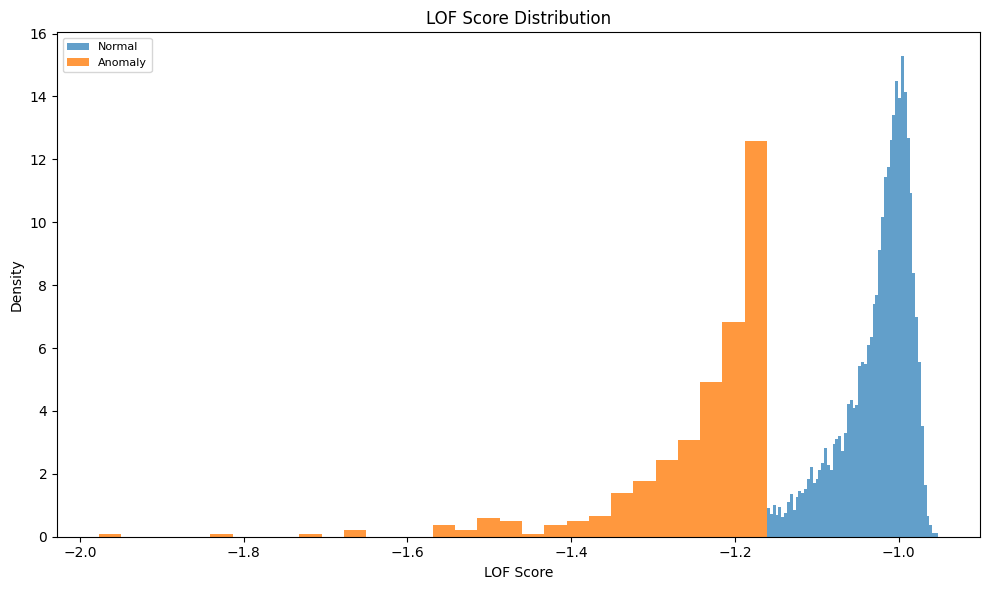

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(lof_scores[~lof_anomaly], bins=60, alpha=0.7, label='Normal', density=True)
ax.hist(lof_scores[lof_anomaly], bins=30, alpha=0.8, label='Anomaly', density=True)
ax.set_title('LOF Score Distribution')
ax.set_xlabel('LOF Score')
ax.set_ylabel('Density')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## 21. Isolation Forest Scores vs Target

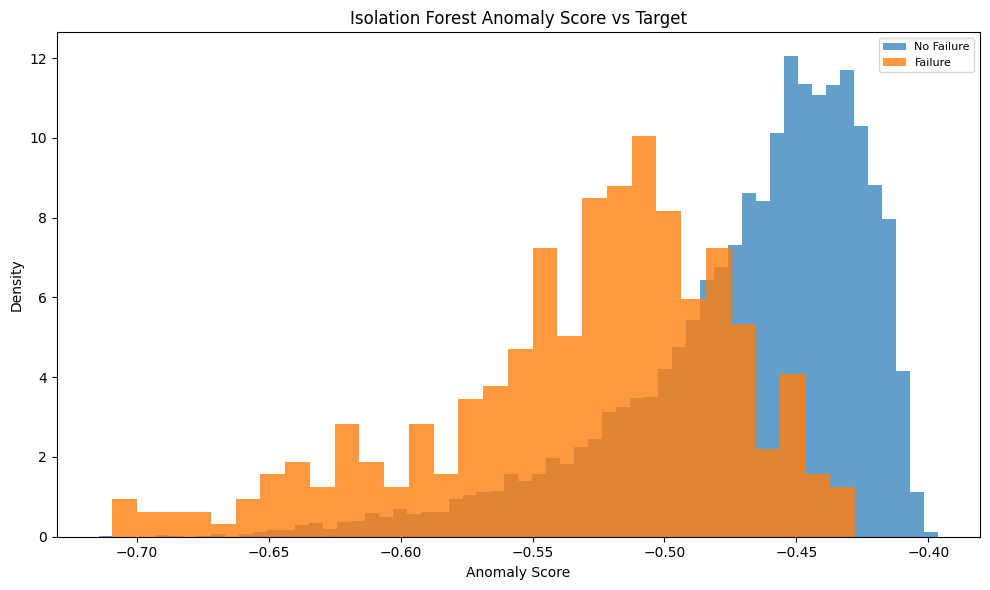

In [31]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(iso_scores[df['Target']==0], bins=60, alpha=0.7, label='No Failure', density=True)
ax.hist(iso_scores[df['Target']==1], bins=30, alpha=0.8, label='Failure', density=True)
ax.set_title('Isolation Forest Anomaly Score vs Target')
ax.set_xlabel('Anomaly Score')
ax.set_ylabel('Density')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## 22. Export EDA Artifacts

In [32]:
joblib.dump({
    'df': df,
    'num_features': num_features,
    'iso_anomaly': iso_anomaly,
}, 'artifacts/eda_artifacts.pkl')

print('Saved: eda_artifacts.pkl')

Saved: eda_artifacts.pkl
